# Extra data exploration: RRCA baseflow

This notebook adds to `eda_start.ipynb`. It looks at four things:

1. Problems in the data
2. Strange things about the data
3. Fair comparisons between rivers and years
4. Patterns that can help the regression

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Same file as project6.ipynb; also works if the CSV sits next to the notebook
file_path = next(p for p in ["data/RRCA_baseflow.csv", "RRCA_baseflow.csv"] if Path(p).exists())
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()
df = df.rename(columns={
    "Date": "date_days",
    "Segment_id": "segment_id",
    "Evapotranspiration": "evapotranspiration",
    "Precipitation": "precipitation",
    "Irrigation_pumping": "irrigation_pumping",
    "Observed": "observed"
})

# Instructor's conversion: days since Jan 1, 1900
df["days_since_1900"] = df["date_days"] - 693963
df["date"] = pd.Timestamp("1900-01-01") + pd.to_timedelta(df["days_since_1900"], unit="D")

# A station is a segment at a specific x/y location (see Section 1b)
df["station"] = df["segment_id"].astype(str) + "_" + df["x"].astype(str)

print(df.shape)
df.head()

(15591, 11)


,date_days,segment_id,x,y,evapotranspiration,precipitation,irrigation_pumping,observed,days_since_1900,date,station
0,710732,144,1086190,14476800,0.59,18.99,0.0,0.145161,16769,1945-11-30,144_1086190
1,710763,144,1086190,14476800,0.97,29.63,0.0,0.445161,16800,1945-12-31,144_1086190
2,710791,144,1086190,14476800,1.34,29.63,0.0,1.332203,16828,1946-01-28,144_1086190
3,710822,144,1086190,14476800,1.79,29.63,0.0,2.932203,16859,1946-02-28,144_1086190
4,710852,144,1086190,14476800,8.23,29.63,0.0,3.728689,16889,1946-03-30,144_1086190


## 1. Problems in the data

### 1a. Missing values hidden as zeros

The data says nothing is missing. But some stations have rain, ET and pumping all equal to 0 in every single month, for many years. That can't be real. These are blanks that were filled with 0.

In [2]:
inputs = ["evapotranspiration", "precipitation", "irrigation_pumping"]

all_zero = (
    df.groupby("station")[inputs]
      .apply(lambda g: (g == 0).all().all())
      .rename("inputs_all_zero")
)
df["inputs_missing"] = df["station"].map(all_zero)

missing_stations = all_zero[all_zero].index.tolist()
print(f"Stations with ALL inputs = 0: {len(missing_stations)} of {df['station'].nunique()}")
print(f"Rows affected: {df['inputs_missing'].sum():,} of {len(df):,} ({df['inputs_missing'].mean():.0%})")
display(
    df[df["inputs_missing"]]
      .groupby("station")
      .agg(rows=("observed", "size"), first_year=("date", lambda s: s.min().year),
           last_year=("date", lambda s: s.max().year), mean_baseflow=("observed", "mean"))
)

Stations with ALL inputs = 0: 9 of 46
Rows affected: 4,337 of 15,591 (28%)


,rows,first_year,last_year,mean_baseflow
station,,,,
145_1207630,399,1944,2000,1.224663
146_1329070,459,1962,2000,2.212100
152_1392430,396,1939,1972,2.833345
171_1381870,246,1944,1964,4.933059
189_1392430,718,1939,1999,2.696089
196_1482190,656,1946,2000,5.479823
51_1154830,495,1959,2000,0.120455
56_1170670,653,1946,2000,3.372105
98_721870,315,1950,1976,0.804866


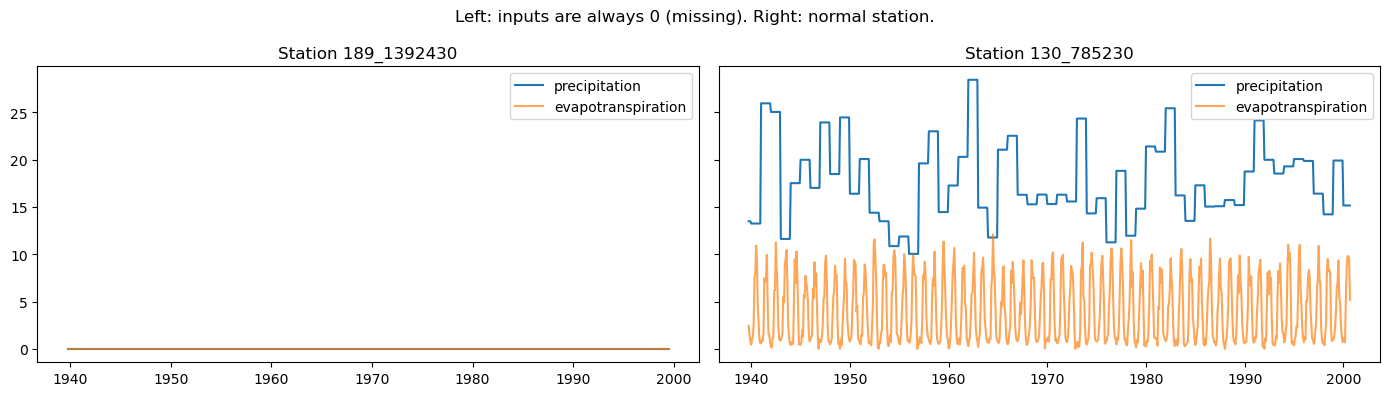

In [3]:
# Compare an affected station with a normal one
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, st in zip(axes, ["189_1392430", "130_785230"]):
    s = df[df["station"] == st].sort_values("date")
    ax.plot(s["date"], s["precipitation"], label="precipitation")
    ax.plot(s["date"], s["evapotranspiration"], label="evapotranspiration", alpha=0.7)
    ax.set_title(f"Station {st}")
    ax.legend()
plt.suptitle("Left: inputs are always 0 (missing). Right: normal station.")
plt.tight_layout()
plt.show()

9 of the 46 stations have this problem. That is about 28% of all rows.

If we leave these zeros in, the regression will think those months had no rain and no pumping, and it will learn the wrong thing. We should remove these stations, mark the values as missing, or add a column that flags them.

### 1b. One segment ID, two stations

Each segment ID should be one place on the river. But segments 53, 152, 159 and 171 each have data from two different locations.

In [4]:
locs = df.groupby("segment_id")["station"].nunique()
two_station_segments = locs[locs > 1].index.tolist()
print("Segments with two stations:", two_station_segments)

display(
    df[df["segment_id"].isin(two_station_segments)]
      .groupby(["segment_id", "x", "y"])
      .agg(rows=("observed", "size"),
           first_year=("date", lambda s: s.min().year),
           last_year=("date", lambda s: s.max().year),
           mean_baseflow=("observed", "mean"))
)

print("Rows sharing the same (date, segment_id):",
      df.duplicated(["date_days", "segment_id"], keep=False).sum())

Segments with two stations: [53, 152, 159, 171]


rows  first_year  last_year  mean_baseflow
segment_id x       y                                                   
53         991150  14714400   120        1940       1950      19.227989
           1049230 14666880   120        1939       1949     104.405916
152        1360750 14529600    60        1995       2000      11.970038
           1392430 14545440   396        1939       1972       2.833345
159        1181230 14656320    90        1940       1948      18.417189
           1218190 14614080   252        1939       1960      24.515931
171        1381870 14460960   246        1944       1964       4.933059
           1508590 14524320   447        1945       2000       4.481307

Rows sharing the same (date, segment_id): 786


Segment 53 is a good example. One of its stations averages about 19 and the other about 104. Mixing them gives an average that fits neither.

To avoid this, we use `station` (segment ID + location) instead of `segment_id`.

### 1c. Negative baseflow

Baseflow is groundwater flowing into the river, so it should not be negative. But 232 rows are below zero.

Rows with observed < 0: 232
Rows with observed = 0: 1244

Negative values by station:


,negative_rows
station,
178_927790,222
176_790510,10


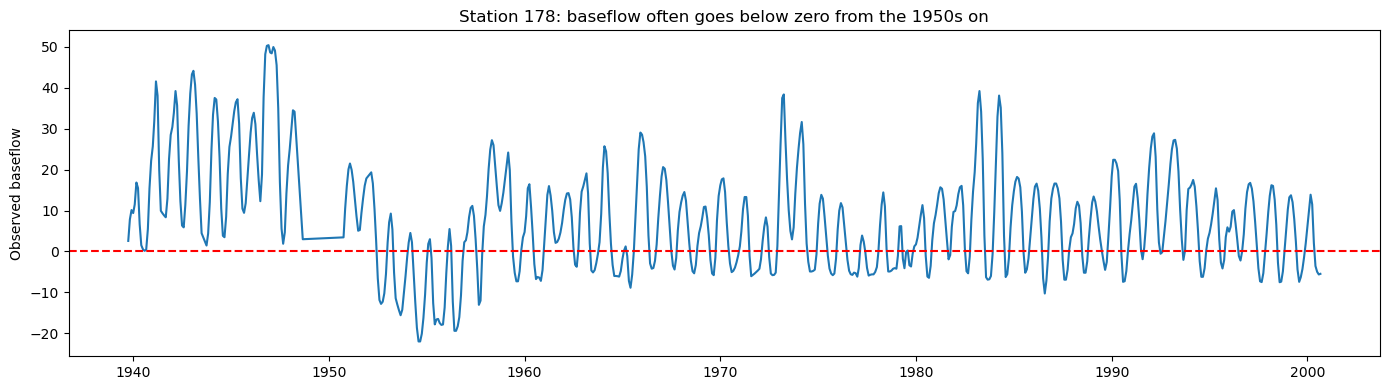

In [5]:
print("Rows with observed < 0:", (df["observed"] < 0).sum())
print("Rows with observed = 0:", (df["observed"] == 0).sum())
print("\nNegative values by station:")
display(df[df["observed"] < 0]["station"].value_counts().to_frame("negative_rows"))

s = df[df["station"] == "178_927790"].sort_values("date")
plt.figure(figsize=(14, 4))
plt.plot(s["date"], s["observed"])
plt.axhline(0, color="red", linestyle="--")
plt.title("Station 178: baseflow often goes below zero from the 1950s on")
plt.ylabel("Observed baseflow")
plt.tight_layout()
plt.show()

Almost all negative values come from station 178. It is normal in the 1940s, but from the 1950s on it drops below zero in about a third to half of the months.

A likely reason: pumping lowered the groundwater so much that, in dry months, the river loses water into the ground.

Negative values also cause a problem later, because you can't take the log of a negative number (see 4d).

## 2. Strange things about the data

### 2a. Precipitation is per year, not per month

The project description says precipitation is for the month. But when we plot one station, precipitation looks like stairs: it stays flat for 12 months, then jumps.

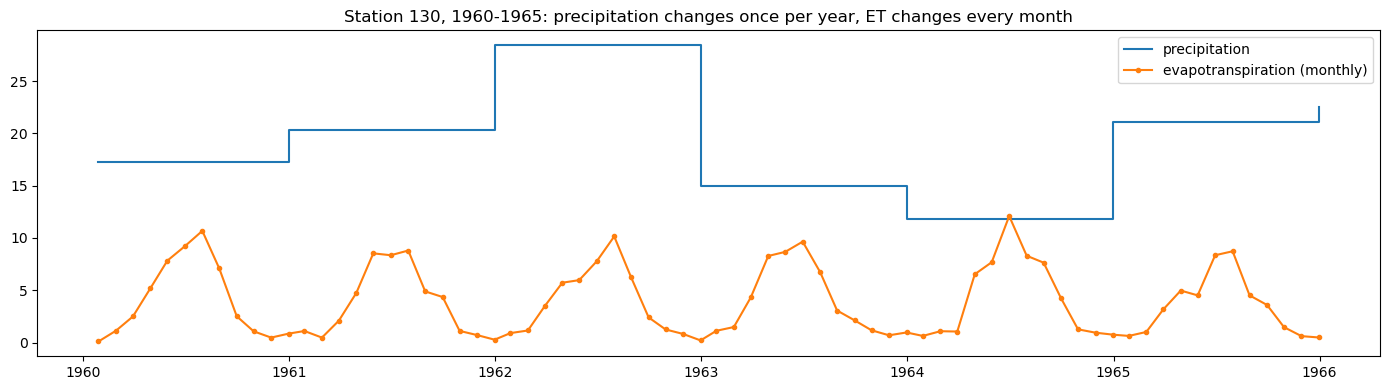

In [6]:
s = df[df["station"] == "130_785230"].sort_values("date")
s = s[(s["date"] >= "1960") & (s["date"] < "1966")]

fig, ax = plt.subplots(figsize=(14, 4))
ax.step(s["date"], s["precipitation"], where="post", label="precipitation")
ax.plot(s["date"], s["evapotranspiration"], marker=".", label="evapotranspiration (monthly)")
ax.set_title("Station 130, 1960-1965: precipitation changes once per year, ET changes every month")
ax.legend()
plt.tight_layout()
plt.show()

So precipitation is really a yearly total, copied into every month. It can show that one year was wetter than another, but it can't explain why summer is different from winter.

ET is different. It really does change every month.

### 2b. The month labels are one month off

After using the instructor's date formula, the dates land on odd days (Dec 31, Jan 28, Feb 28, ...). If we take the month from these dates, the labels look one month too early:

- Irrigation pumping seems to start in May, but farmers here irrigate June to September.
- The yearly precipitation value changes in "December" instead of January.

Adding 16 days to each date fixes this.

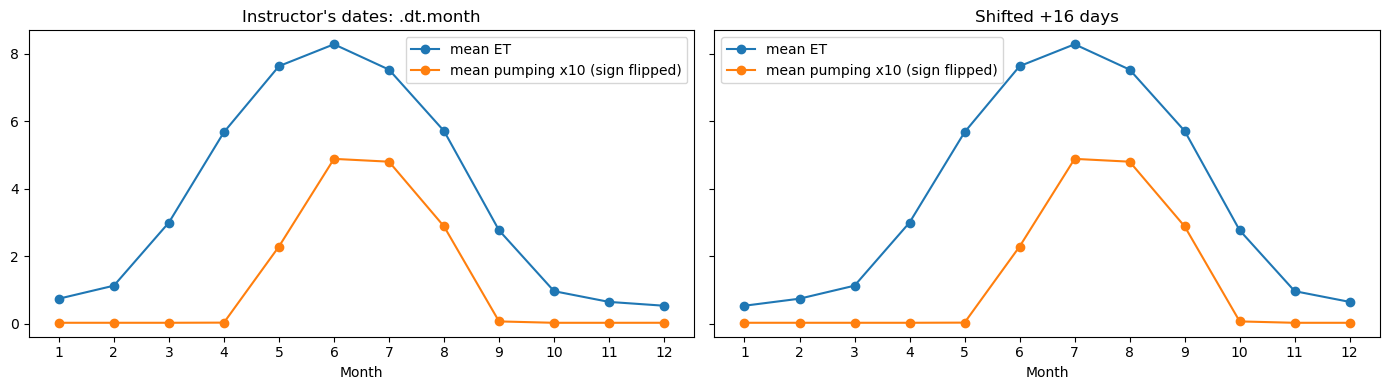

Month label where precipitation changes (raw):   {12: 61, 9: 1}
Month label where precipitation changes (fixed): {1: 61, 10: 1}
Station-years with one precipitation value (raw year): 7%
Station-years with one precipitation value (fixed year): 100%


In [7]:
df["month_raw"] = df["date"].dt.month
df["date_fixed"] = df["date"] + pd.Timedelta(days=16)
df["month"] = df["date_fixed"].dt.month
df["year"] = df["date_fixed"].dt.year

real = df[~df["inputs_missing"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, col, title in [(axes[0], "month_raw", "Instructor's dates: .dt.month"),
                       (axes[1], "month", "Shifted +16 days")]:
    m = real.groupby(col)[["evapotranspiration", "irrigation_pumping"]].mean()
    ax.plot(m.index, m["evapotranspiration"], marker="o", label="mean ET")
    ax.plot(m.index, -m["irrigation_pumping"] * 10, marker="o", label="mean pumping x10 (sign flipped)")
    ax.set_xticks(range(1, 13))
    ax.set_title(title)
    ax.set_xlabel("Month")
    ax.legend()
plt.tight_layout()
plt.show()

# Where does the yearly precipitation value change?
s = df[df["station"] == "130_785230"].sort_values("date")
changes = s[s["precipitation"].diff() != 0]
print("Month label where precipitation changes (raw):  ", changes["month_raw"].value_counts().head(3).to_dict())
print("Month label where precipitation changes (fixed):", changes["month"].value_counts().head(3).to_dict())

# With fixed years, each station-year has exactly one precipitation value
for name, yr in [("raw year", real["date"].dt.year), ("fixed year", real["year"])]:
    n = real.groupby(["station", yr])["precipitation"].nunique()
    print(f"Station-years with one precipitation value ({name}): {(n == 1).mean():.0%}")

After the fix, ET is highest in July and pumping happens June to September. That matches the farming season.

With the original labels, only 7% of station-years have one precipitation value. After the fix, 100% do.

For the regression, this fix doesn't change the predictions, because the months just get new names. It matters when we describe the seasons. The rest of this notebook uses the fixed `month` and `year`.

## 3. Fair comparisons

### 3a. Which stations are measured each year?

Stations start and stop recording at different times. So when the average changes, it might be because the rivers changed, or just because different rivers are being measured.

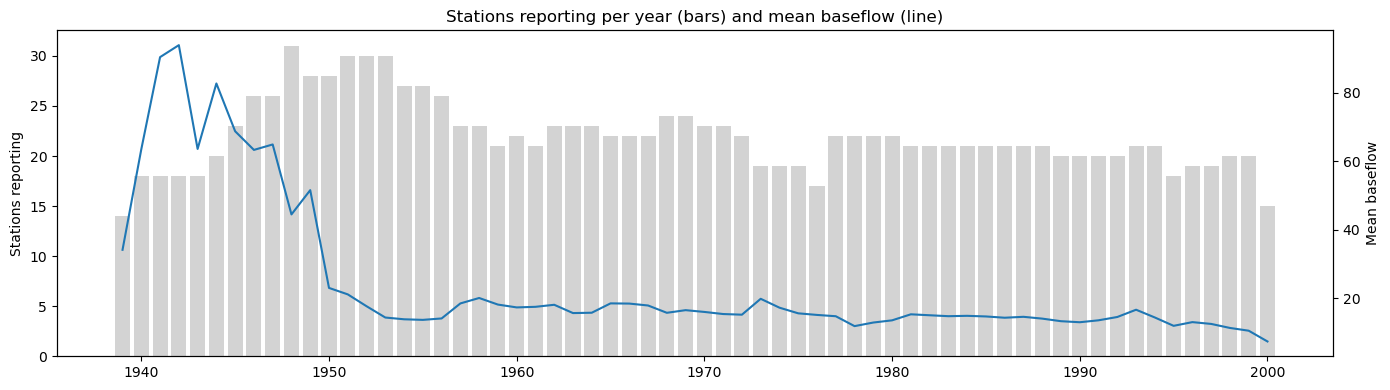

,mean_baseflow,first_year,last_year
station,,,
256_1941550,393.717475,1939,1949
239_1630030,374.032201,1939,1949
194_970030,106.247555,1939,1945
53_1049230,104.405916,1939,1949


In [8]:
per_year = df.groupby("year").agg(
    stations=("station", "nunique"),
    mean_baseflow=("observed", "mean")
)

fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.bar(per_year.index, per_year["stations"], color="lightgray", label="stations reporting")
ax1.set_ylabel("Stations reporting")
ax2 = ax1.twinx()
ax2.plot(per_year.index, per_year["mean_baseflow"], color="tab:blue", label="mean baseflow")
ax2.set_ylabel("Mean baseflow")
ax1.set_title("Stations reporting per year (bars) and mean baseflow (line)")
plt.tight_layout()
plt.show()

big = df.groupby("station")["observed"].mean().sort_values(ascending=False).head(4)
display(
    df[df["station"].isin(big.index)]
      .groupby("station")
      .agg(mean_baseflow=("observed", "mean"), first_year=("year", "min"), last_year=("year", "max"))
      .sort_values("mean_baseflow", ascending=False)
)

The two biggest stations (segments 239 and 256, averaging about 375–395) stop after 1949. When they leave, the overall average drops sharply.

So the big drop after the 1940s in `project6.ipynb` is mostly because these big rivers left the data, not because the rivers dried up.

### 3b. The real trend

To see the real trend, we only keep stations that were measured in at least 6 decades.

15 long-running stations (6+ decades)


,all rows,long-running stations
decade,,
1930,34.2,16.0
1940,66.7,22.8
1950,17.4,22.0
1960,17.2,20.3
1970,15.4,16.6
1980,14.5,16.0
1990,13.2,12.2
2000,7.4,7.0


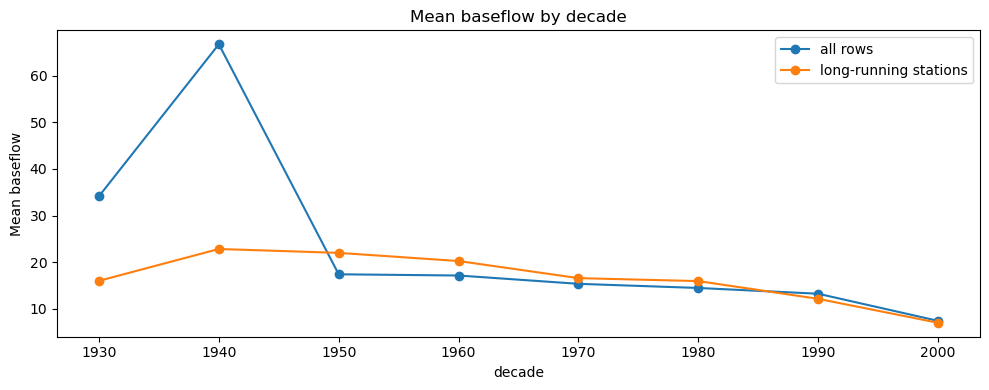

In [9]:
decade = (df["year"] // 10) * 10
decades_per_station = df.assign(decade=decade).groupby("station")["decade"].nunique()
long_running = decades_per_station[decades_per_station >= 6].index

trend = (
    df.assign(decade=decade)
      .assign(group=np.where(df["station"].isin(long_running), "long-running stations", "all rows"))
)
summary = pd.concat([
    trend.groupby("decade")["observed"].mean().rename("all rows"),
    trend[trend["station"].isin(long_running)].groupby("decade")["observed"].mean().rename("long-running stations")
], axis=1)
print(f"{len(long_running)} long-running stations (6+ decades)")
display(summary.round(1))

summary.plot(marker="o", figsize=(10, 4), title="Mean baseflow by decade")
plt.ylabel("Mean baseflow")
plt.tight_layout()
plt.show()

For these stations, baseflow is about 20–23 in the 1940s–1960s, then slowly goes down: about 16 in the 1970s–80s, about 12 in the 1990s and about 7 in 2000.

So there is a real decline, but it is slow, not a sudden crash after 1949.

This matters for testing: if we train on older years and test on the 1990s, the model will probably guess too high.

### 3c. Comparing big and small rivers fairly

Big rivers hide small creeks in every plot. To compare them, we divide each station's baseflow by its own average. A value of 1 means "normal for this river", 1.2 means "20% above normal", and so on.

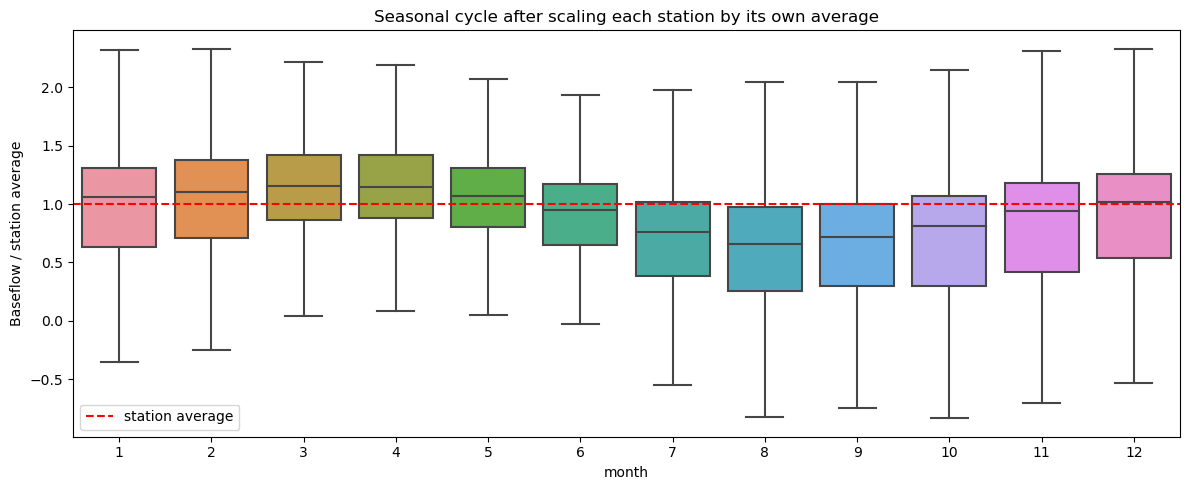

Peak month per station: {3: 21, 4: 12, 2: 5, 11: 2, 5: 2, 1: 1, 6: 1, 7: 1, 8: 1}
Lowest month per station: {8: 27, 10: 7, 9: 6, 7: 3, 5: 1, 3: 1, 6: 1}


In [10]:
df["baseflow_vs_station_avg"] = df["observed"] / df.groupby("station")["observed"].transform("mean")

plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="month", y="baseflow_vs_station_avg", showfliers=False)
plt.axhline(1, color="red", linestyle="--", label="station average")
plt.title("Seasonal cycle after scaling each station by its own average")
plt.ylabel("Baseflow / station average")
plt.legend()
plt.tight_layout()
plt.show()

season = df.groupby(["station", "month"])["baseflow_vs_station_avg"].mean().unstack()
print("Peak month per station:", season.idxmax(axis=1).value_counts().to_dict())
print("Lowest month per station:", season.idxmin(axis=1).value_counts().to_dict())

Almost every river follows the same yearly pattern:

- Highest in March–April (about 15% above normal)
- Lowest in August (about 35% below normal), because summer heat and irrigation pumping take water out of the ground

The swing is a percentage of each river's size: big rivers drop a lot, small creeks drop a little. Plain linear regression adds the same amount to every river, so it can't capture this well. Using the log of baseflow (see 4d) helps.

## 4. Patterns that can help the regression

### 4a. Does pumping lower baseflow?

Across all the data, pumping and baseflow seem unrelated, because big and small rivers are mixed together. So we look inside each station, year by year.

Note: pumping is stored as a negative number, because water is being removed.

In [11]:
annual = (
    df[~df["inputs_missing"]]
      .groupby(["station", "year"])
      .agg(baseflow=("observed", "mean"),
           pumping=("irrigation_pumping", "sum"),
           precipitation=("precipitation", "first"),
           months=("observed", "size"))
      .reset_index()
)
annual = annual[annual["months"] == 12].sort_values(["station", "year"])
annual["precipitation_prev_year"] = annual.groupby("station")["precipitation"].shift(1)

per_station = []
for st, g in annual.groupby("station"):
    if len(g) >= 10:
        per_station.append({
            "station": st,
            "years": len(g),
            "corr_pumping": g["baseflow"].corr(g["pumping"]),
            "corr_precip_same_year": g["baseflow"].corr(g["precipitation"]),
            "corr_precip_prev_year": g["baseflow"].corr(g["precipitation_prev_year"]),
        })
per_station = pd.DataFrame(per_station).set_index("station")
display(per_station.round(2))
print("Median correlations across stations:")
print(per_station.median(numeric_only=True).round(2))

,years,corr_pumping,corr_precip_same_year,corr_precip_prev_year
station,,,,
130_785230,60,0.82,0.18,0.01
135_1223470,21,0.88,-0.29,-0.56
138_1434670,22,0.31,0.22,0.25
147_906670,53,0.92,-0.04,-0.03
148_1703950,34,0.43,0.26,0.28
149_1387150,39,-0.42,0.52,0.43
157_1022830,10,-0.67,0.70,0.08
159_1218190,20,0.01,0.47,0.21
170_1270990,48,0.46,0.24,-0.03


Median correlations across stations:
years                    39.00
corr_pumping              0.42
corr_precip_same_year     0.27
corr_precip_prev_year     0.07
dtype: float64


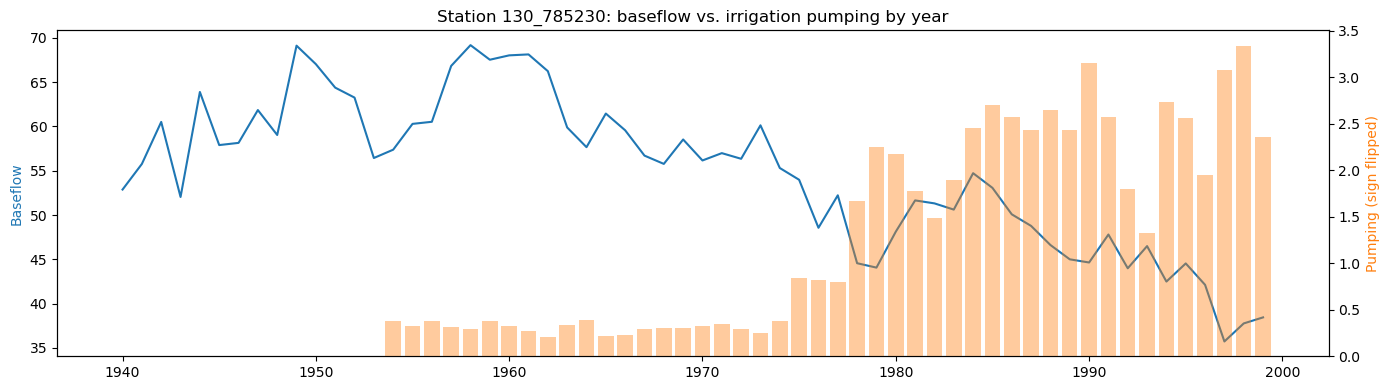

In [12]:
# Example: the station with the most years of real input data
st = per_station["years"].idxmax()
g = annual[annual["station"] == st]

fig, ax1 = plt.subplots(figsize=(14, 4))
ax1.plot(g["year"], g["baseflow"], color="tab:blue", label="annual mean baseflow")
ax1.set_ylabel("Baseflow", color="tab:blue")
ax2 = ax1.twinx()
ax2.bar(g["year"], -g["pumping"], color="tab:orange", alpha=0.4, label="annual pumping (sign flipped)")
ax2.set_ylabel("Pumping (sign flipped)", color="tab:orange")
ax1.set_title(f"Station {st}: baseflow vs. irrigation pumping by year")
plt.tight_layout()
plt.show()

At about 3 out of 4 stations, years with more pumping have less baseflow.

Because pumping is negative, this shows up as a positive correlation (about +0.4). Keep this in mind when reading regression coefficients: a positive coefficient on pumping means more pumping, less baseflow.

One caution: pumping went up over the years while baseflow went down, so part of this link may just be both changing over time.

### 4b. Does rain matter? This year or last year?

Groundwater moves slowly, so maybe last year's rain matters more than this year's.

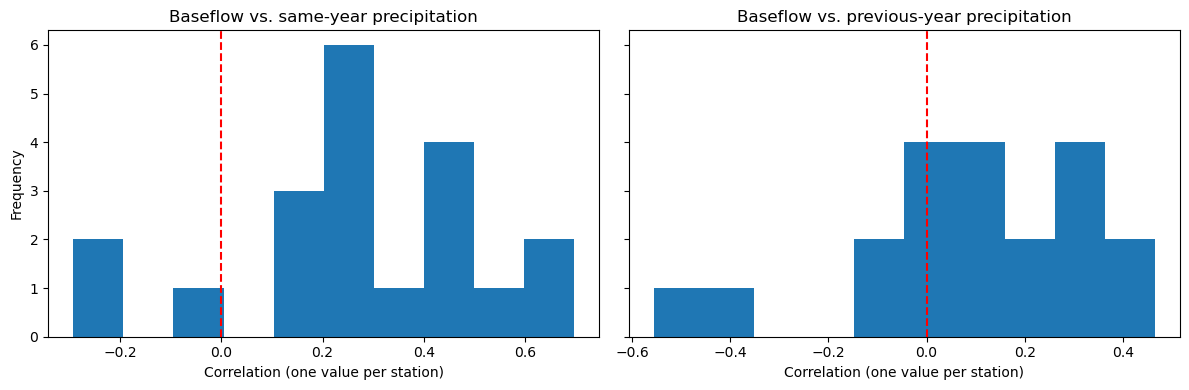

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
per_station["corr_precip_same_year"].plot.hist(ax=axes[0], bins=10, title="Baseflow vs. same-year precipitation")
per_station["corr_precip_prev_year"].plot.hist(ax=axes[1], bins=10, title="Baseflow vs. previous-year precipitation")
for ax in axes:
    ax.axvline(0, color="red", linestyle="--")
    ax.set_xlabel("Correlation (one value per station)")
plt.tight_layout()
plt.show()

This year's rain has a weak link to baseflow (about +0.27). Last year's rain has almost no link (about +0.07).

Rain helps a little, but much less than which river it is and what season it is.

### 4c. This month vs. last month

Baseflow is groundwater draining slowly, so it shouldn't jump around much from month to month.

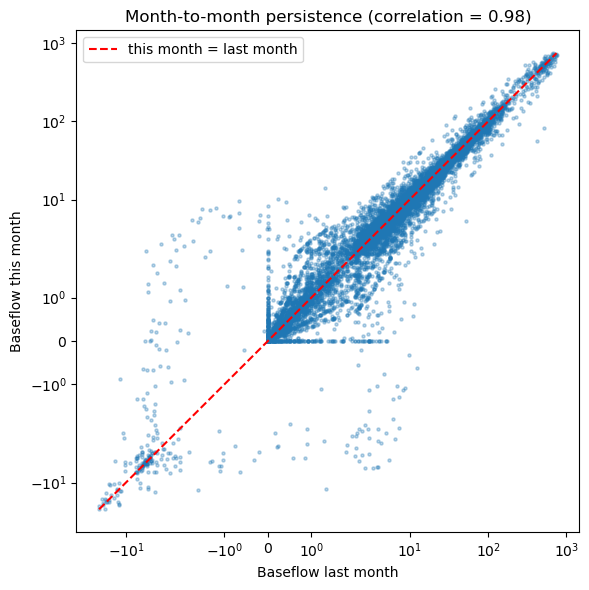

In [14]:
df = df.sort_values(["station", "date"])
df["observed_last_month"] = df.groupby("station")["observed"].shift(1)

pair = df.dropna(subset=["observed_last_month"])
r = pair["observed"].corr(pair["observed_last_month"])

plt.figure(figsize=(6, 6))
plt.scatter(pair["observed_last_month"], pair["observed"], s=5, alpha=0.3)
lim = [pair["observed"].min(), pair["observed"].max()]
plt.plot(lim, lim, color="red", linestyle="--", label="this month = last month")
plt.xscale("symlog")
plt.yscale("symlog")
plt.xlabel("Baseflow last month")
plt.ylabel("Baseflow this month")
plt.title(f"Month-to-month persistence (correlation = {r:.2f})")
plt.legend()
plt.tight_layout()
plt.show()

This month's baseflow is almost the same as last month's (correlation about 0.96). Two things follow:

1. Don't split the data into train and test at random. Neighboring months are almost copies, so the model would basically see the test answers. Split by time instead: train on older years, test on the 1990s (like the paper).
2. Last month's baseflow would be a very strong predictor. Whether we're allowed to use it depends on whether we'd really know last month's value when making a prediction.

### 4d. Most baseflow values are small, a few are huge

Most values are small, but a few big rivers reach several hundred. These huge values can take over a linear regression.

C:\Users\Drish\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Drish\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Drish\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


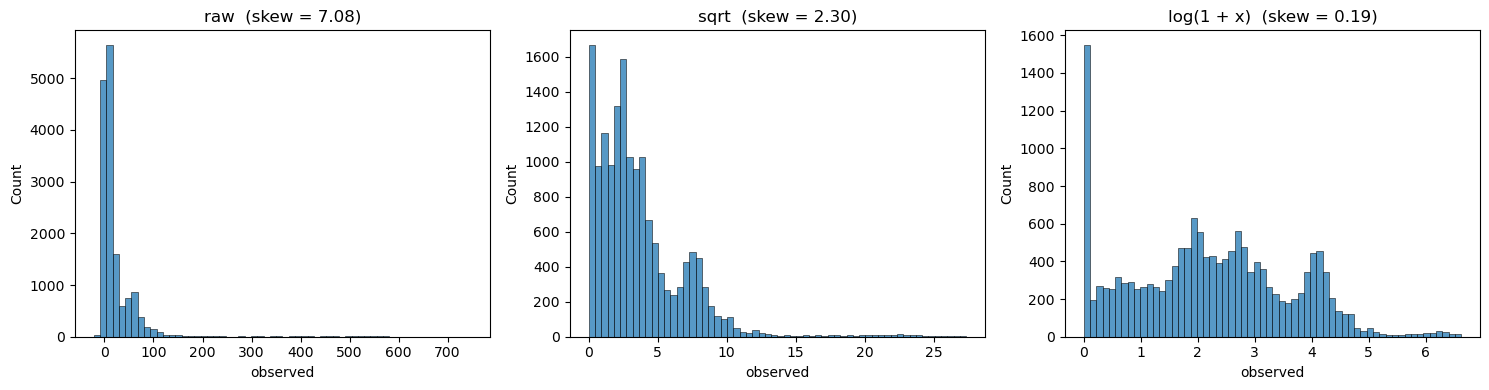

In [15]:
clipped = df["observed"].clip(lower=0)  # log/sqrt need non-negative values (see 1c)
versions = {
    "raw": df["observed"],
    "sqrt": np.sqrt(clipped),
    "log(1 + x)": np.log1p(clipped),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, values) in zip(axes, versions.items()):
    sns.histplot(values, bins=60, ax=ax)
    ax.set_title(f"{name}  (skew = {values.skew():.2f})")
plt.tight_layout()
plt.show()

Taking the log makes the values much more balanced (skew drops from about 7 to about 0.2). So predicting the log of baseflow will probably work better.

The catch: log doesn't work on negative numbers, so the 232 negative values need to be removed or adjusted first.

## Summary

| What we found | What to do in the regression |
|---|---|
| 9 stations (~28% of rows) have fake zeros for all inputs | Remove them, mark as missing, or flag them |
| 4 segment IDs contain two stations | Use `station` instead of `segment_id` |
| Precipitation is a yearly value | It can only help explain differences between years |
| Month labels are one month early | Use date + 16 days when describing seasons |
| Big rivers stop being measured after 1949 | Don't trust the all-rows yearly average as the real trend |
| Baseflow slowly declines, lowest in the 1990s | A model trained on older years may guess too high |
| The seasonal swing is a percentage of river size | Try predicting the log of baseflow |
| More pumping goes with less baseflow | Pumping is negative, so expect a positive coefficient |
| This month ≈ last month (0.96) | Split train/test by time, not randomly |
| A few huge values | Use log of baseflow (handle negatives first) |